# Modelos preentrenados (no smoke: descarga ~2 GB)

El tokenizador de XLM-R y el espacio multilingüe de e5, los dos modelos que usa el proyecto.

In [1]:
import matplotlib.pyplot as plt

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)

In [2]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("xlm-roberta-base")
for w in ["aprendizaje", "learning", "moniliasis", "investigación", "research", "prerrequisito"]:
    print(f"{w:15s} → {tok.tokenize(w)}")

/Users/sergiomonsalve/Code/MIA/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


aprendizaje     → ['▁aprendizaje']
learning        → ['▁learning']
moniliasis      → ['▁moni', 'li', 'asis']
investigación   → ['▁investigación']
research        → ['▁research']
prerrequisito   → ['▁pre', 'rre', 'quisito']


Las palabras frecuentes son un solo token en español y en inglés («aprendizaje», «research»); las raras o técnicas se parten («moniliasis» → `▁moni` `li` `asis`). Con 250 000 tokens repartidos entre 100 idiomas, el español común queda bien cubierto y el vocabulario de un campo especializado no.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 24850.14it/s]

aprendizaje por refuerzo ~ reinforcement learning: 0.86
proceso de decisión de Markov ~ Markov decision process: 0.92
aprendizaje por refuerzo ~ gato doméstico: 0.77


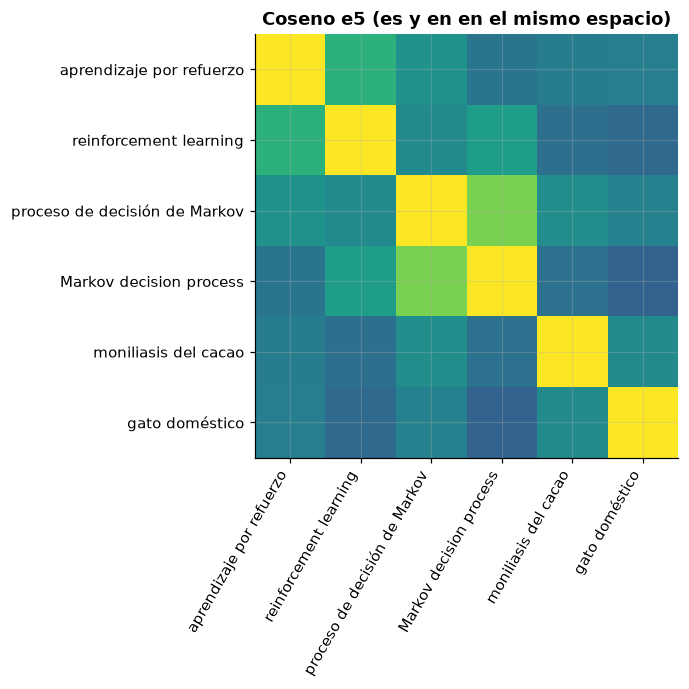

In [3]:
from research_paths.retrieval import e5_encoder

enc = e5_encoder()
phrases = [
    "aprendizaje por refuerzo",
    "reinforcement learning",
    "proceso de decisión de Markov",
    "Markov decision process",
    "moniliasis del cacao",
    "gato doméstico",
]
V = enc(phrases, "query")
S = V @ V.T
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(S, vmin=0.6, vmax=1, cmap="viridis")
ax.set_xticks(range(6), phrases, rotation=60, ha="right")
ax.set_yticks(range(6), phrases)
ax.set_title("Coseno e5 (es y en en el mismo espacio)")
for i, j in [(0, 1), (2, 3), (0, 5)]:
    print(f"{phrases[i]} ~ {phrases[j]}: {S[i, j]:.2f}")

e5 concentra los cosenos entre 0,7 y 1, así que importa el **orden**, no el valor: la traducción (0,86 y 0,92) queda por encima de un par sin relación (0,77). Por eso el proyecto usa e5 para ordenar candidatos y no un umbral fijo de similitud.